Using device: cpu


config.json:   0%|          | 0.00/477 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...


Dataset sample:


,sentence,label,idx
0,it gets onto the screen just about as much of ...,1,726
1,my big fat greek wedding uses stereotypes in a...,1,737
2,"for the most part , director anne-sophie birot...",1,51
3,cq 's reflection of artists and the love of ci...,1,482
4,charles ' entertaining film chronicles seinfel...,1,426



Number of evaluated sentences: 500

BERT Evaluation Metrics:


,Score
Accuracy,0.918
Precision,0.923
Recall,0.920
F1-score,0.921



Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.92      0.91       239
    Positive       0.92      0.92      0.92       261

    accuracy                           0.92       500
   macro avg       0.92      0.92      0.92       500
weighted avg       0.92      0.92      0.92       500



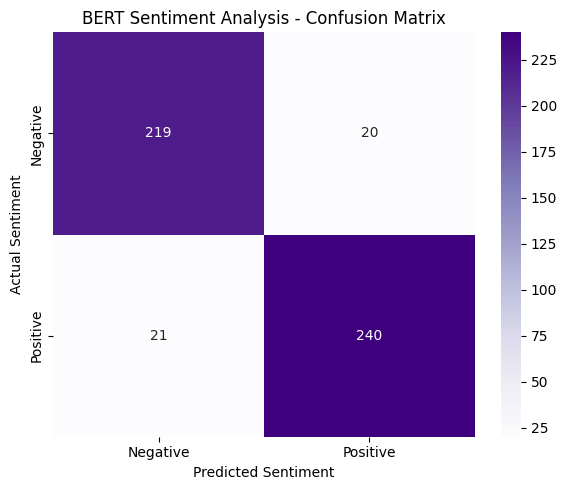


Number of misclassified sentences: 41

Most confident incorrect predictions:


,Sentence,Actual Label,Predicted Label,Positive Probability,Prediction Confidence
282,"the lower your expectations , the more you 'll...",0,1,0.999311,0.999311
184,it 's everything you do n't go to the movies f...,0,1,0.999016,0.999016
278,as unseemly as its title suggests .,1,0,0.001850,0.998150
460,while there 's something intrinsically funny a...,1,0,0.002102,0.997898
366,although huppert 's intensity and focus has a ...,0,1,0.997003,0.997003
327,"movie fans , get ready to take off ... the oth...",0,1,0.996455,0.996455
481,every nanosecond of the the new guy reminds yo...,0,1,0.996436,0.996436
183,"you wo n't like roger , but you will quickly r...",0,1,0.995712,0.995712
324,harrison 's flowers puts its heart in the righ...,1,0,0.004314,0.995686
244,reign of fire looks as if it was made without ...,1,0,0.004459,0.995541



Custom Sentence Predictions:

Sentence: The story was slow, but the ending was wonderful.
Predicted sentiment: Positive
Positive probability: 0.999

Sentence: This movie was terrible and a complete waste of time.
Predicted sentiment: Negative
Positive probability: 0.001

Sentence: I really enjoyed the acting and the beautiful visuals.
Predicted sentiment: Positive
Positive probability: 1.000

Sentence: The film was boring and poorly written.
Predicted sentiment: Negative
Positive probability: 0.001

Prediction and evaluation CSV files saved.
Practical 8 completed successfully.


In [1]:

# ============================================================
# DEEP LEARNING PRACTICAL 8
# Pre-trained BERT for Sentiment Analysis
# Dataset: SST-2
# ============================================================

# 1. Install required libraries
%pip install -q transformers datasets accelerate scikit-learn seaborn

# 2. Import libraries
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

# 3. Set random seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Use GPU when available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 4. Load the pretrained BERT model and tokenizer
# This model is already fine-tuned for binary sentiment classification.
MODEL_NAME = "textattack/bert-base-uncased-SST-2"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME
).to(device)

# Set evaluation mode because we are evaluating an existing model.
model.eval()

print("BERT model loaded successfully!")

# 5. Load the SST-2 validation dataset
# SST-2 contains sentences labeled as negative (0) or positive (1).
dataset = load_dataset("nyu-mll/glue", "sst2", split="validation")

# Select 500 samples for a faster practical demonstration.
sample = dataset.shuffle(seed=SEED).select(
    range(min(500, len(dataset)))
)

print("\nDataset sample:")
display(pd.DataFrame(sample[:5]))

print("\nNumber of evaluated sentences:", len(sample))

# 6. Create a prediction function
# Process sentences in batches to reduce memory usage.
@torch.no_grad()
def predict_texts(texts, batch_size=32):
    predictions = []
    positive_probabilities = []

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        # Convert text into BERT input tokens.
        encoded = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(device)

        # Convert model outputs into class probabilities.
        logits = model(**encoded).logits
        probabilities = torch.softmax(logits, dim=-1)

        # Class 0 = negative, Class 1 = positive.
        predictions.extend(
            probabilities.argmax(dim=-1).cpu().tolist()
        )
        positive_probabilities.extend(
            probabilities[:, 1].cpu().tolist()
        )

    return (
        np.array(predictions),
        np.array(positive_probabilities)
    )

# 7. Predict sentiments for the dataset
texts = sample["sentence"]
y_true = np.array(sample["label"])

y_pred, positive_probability = predict_texts(texts)

# 8. Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="binary",
    zero_division=0
)

metrics = pd.Series({
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
})

print("\nBERT Evaluation Metrics:")
display(metrics.round(3).to_frame("Score"))

# Display detailed class-wise performance.
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

# 9. Plot the confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("BERT Sentiment Analysis - Confusion Matrix")
plt.tight_layout()
plt.show()

# 10. Analyze misclassified sentences
review = pd.DataFrame({
    "Sentence": texts,
    "Actual Label": y_true,
    "Predicted Label": y_pred,
    "Positive Probability": positive_probability
})

# Keep only predictions that do not match the actual labels.
mistakes = review[
    review["Actual Label"] != review["Predicted Label"]
].copy()

# Calculate confidence in the predicted class.
mistakes["Prediction Confidence"] = np.where(
    mistakes["Predicted Label"] == 1,
    mistakes["Positive Probability"],
    1 - mistakes["Positive Probability"]
)

print("\nNumber of misclassified sentences:", len(mistakes))
print("\nMost confident incorrect predictions:")

display(
    mistakes.sort_values(
        "Prediction Confidence",
        ascending=False
    ).head(10)
)

# 11. Test BERT on custom sentences
custom_texts = [
    "The story was slow, but the ending was wonderful.",
    "This movie was terrible and a complete waste of time.",
    "I really enjoyed the acting and the beautiful visuals.",
    "The film was boring and poorly written."
]

custom_predictions, custom_probabilities = predict_texts(
    custom_texts
)

print("\nCustom Sentence Predictions:")

for text, label, probability in zip(
    custom_texts,
    custom_predictions,
    custom_probabilities
):
    sentiment = "Positive" if label == 1 else "Negative"

    print(f"\nSentence: {text}")
    print(f"Predicted sentiment: {sentiment}")
    print(f"Positive probability: {probability:.3f}")

# 12. Save evaluation results
review.to_csv(
    "/content/bert_sentiment_predictions.csv",
    index=False
)

metrics.to_csv(
    "/content/bert_evaluation_metrics.csv",
    header=["Score"]
)

print("\nPrediction and evaluation CSV files saved.")
print("Practical 8 completed successfully.")
